# Gaussian Naive Bayes from Scratch

Team members:

| Student name | ID |
| --- | --- |
| Youssef Ahmed Abd El-Tawab Nagy | 20240677 |
| Saged Amr Adel | 20240229 |


### Imports & Data Loading


In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer

np.random.seed(42)

data = load_breast_cancer()
X = data.data
y = data.target

### Stratified Train/Test Split

Split the data into training and test sets while preserving class proportions.


In [2]:
def train_test_split(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)

    train_indices = []
    test_indices = []

    for label in np.unique(y):
        indices = np.where(y == label)[0]
        rng.shuffle(indices)

        n_test = int(round(len(indices) * test_size))

        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices], X[test_indices],
        y[train_indices], y[test_indices]
    )

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Training shape: (456, 30)
Testing shape: (113, 30)
Training class counts: [170 286]
Testing class counts: [42 71]


### Feature Standardization

Standardize both sets using training statistics. GNB does not require scaling; accuracy changed from 93.81% to 92.92% because variance smoothing depends on feature scales.


In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

### Gaussian Naive Bayes 
$$P(C | x) \propto P(C) \cdot \prod_i P(x_i | C)$$

Estimate class means, variances and priors, then predict using log-likelihoods and variance smoothing.


In [5]:
class GaussianNaiveBayes:

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.classes = np.unique(y)

        self.theta_ = np.array([
            X[y == c].mean(axis=0)
            for c in self.classes
        ])

        self.var_ = np.array([
            X[y == c].var(axis=0)
            for c in self.classes
        ])

        counts = np.array([
            np.sum(y == c)
            for c in self.classes
        ])

        self.class_prior_ = counts / len(y)

        epsilon = (
            self.var_smoothing
            * np.var(X, axis=0).max()
        )

        self.epsilon_ = epsilon
        self.var_ += epsilon

        return self

    def predict_proba(self, X):
        log_probs = []

        for i, c in enumerate(self.classes):
            mean = self.theta_[i]
            var = self.var_[i]

            log_likelihood = -0.5 * np.sum(
                np.log(2 * np.pi * var)
                + ((X - mean) ** 2) / var,
                axis=1
            )

            log_prior = np.log(self.class_prior_[i])
            log_probs.append(log_likelihood + log_prior)

        log_probs = np.array(log_probs).T
        log_probs -= log_probs.max(axis=1, keepdims=True)
        probabilities = np.exp(log_probs)

        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        indices = np.argmax(probabilities, axis=1)
        return self.classes[indices]

In [6]:
model = GaussianNaiveBayes()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
raw_accuracy = np.mean(y_pred == y_test)
print("Without Standardization — Accuracy (%):", raw_accuracy * 100)

Without Standardization — Accuracy (%): 93.80530973451327


In [7]:
scaled_model = GaussianNaiveBayes()
scaled_model.fit(X_train_scaled, y_train)
scaled_pred = scaled_model.predict(X_test_scaled)
scaled_accuracy = np.mean(scaled_pred == y_test)
print("With Standardization — Accuracy (%):", scaled_accuracy * 100)

With Standardization — Accuracy (%): 92.92035398230088


### Sanity Check

With smoothing disabled, the manual calculations are:

- Class 0: mean = (1 + 3)/2 = 2; variance = ((1 − 2)² + (3 − 2)²)/2 = 1.
- Class 1: mean = (5 + 7)/2 = 6; variance = ((5 − 6)² + (7 − 6)²)/2 = 1.
- Priors: 2/4 = 0.5 each. At x = 2, the likelihoods are 1/√(2π) and exp(−8)/√(2π).
- Posterior: P(0|2) = 1/(1 + exp(−8)) = 0.99966465; P(1|2) = 0.00033535.

The code verifies these values.


In [8]:
X_tiny = np.array([
    [1.0],
    [3.0],
    [5.0],
    [7.0]
])

y_tiny = np.array([0, 0, 1, 1])

tiny_model = GaussianNaiveBayes(var_smoothing=0)
tiny_model.fit(X_tiny, y_tiny)

print("\n--- Sanity Test ---")
print("Classes:", tiny_model.classes)
print("Means:", tiny_model.theta_.flatten())
print("Variances:", tiny_model.var_.flatten())
print("Class priors:", tiny_model.class_prior_)

sample = np.array([[2.0]])

print("Sample:", sample.flatten())
print("Posterior probabilities:", tiny_model.predict_proba(sample))
print("Predicted class:", tiny_model.predict(sample)[0])

manual_p0 = 1 / (1 + np.exp(-8))
assert np.allclose(tiny_model.theta_, [[2], [6]])
assert np.allclose(tiny_model.var_, [[1], [1]])
assert np.allclose(tiny_model.predict_proba(sample), [[manual_p0, 1 - manual_p0]])
print("Manual sanity check: PASSED")


--- Sanity Test ---
Classes: [0 1]
Means: [2. 6.]
Variances: [1. 1.]
Class priors: [0.5 0.5]
Sample: [2.]
Posterior probabilities: [[9.9966465e-01 3.3535013e-04]]
Predicted class: 0
Manual sanity check: PASSED


### Evaluation Metrics from Scratch

Calculate accuracy, confusion matrices, precision, recall, F1 and macro averages from scratch; return zero for zero denominators.


In [9]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred, classes):
    k = len(classes)
    cm = np.zeros((k, k), dtype=int)

    for i, actual in enumerate(classes):
        for j, predicted in enumerate(classes):
            cm[i, j] = np.sum(
                (y_true == actual) & (y_pred == predicted)
            )

    return cm


def precision_recall_f1(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred, classes)
    results = {}

    for i, c in enumerate(classes):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        results[c] = {
            "precision": precision,
            "recall": recall,
            "f1": f1
        }

    macro = {
        metric: np.mean([results[c][metric] for c in classes])
        for metric in ["precision", "recall", "f1"]
    }

    return results, macro

### Synthetic Test Data

In [10]:
X_tiny_test = np.array([[1.5], [2.5], [5.5], [6.5]])
y_tiny_test = np.array([0, 0, 1, 1])
tiny_pred = tiny_model.predict(X_tiny_test)

### Evaluation & Confusion Matrix Heatmaps

Evaluate both datasets on separate test samples and display their confusion matrices.


In [11]:
import matplotlib.pyplot as plt

def evaluate(y_true, y_pred, classes, name):
    cm = confusion_matrix(y_true, y_pred, classes)
    results, macro = precision_recall_f1(y_true, y_pred, classes)

    print(name)
    print(f"Accuracy: {accuracy(y_true, y_pred):.2%}")
    print(cm)
    for c, scores in results.items():
        print(f"Class {c}:", {m: round(v, 4) for m, v in scores.items()})
    print("Macro:", {m: round(v, 4) for m, v in macro.items()})

    plt.figure()
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.xticks(range(len(classes)), classes)
    plt.yticks(range(len(classes)), classes)
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title(name + " Confusion Matrix")
    plt.tight_layout()
    plt.show()
    plt.close()

Breast Cancer
Accuracy: 93.81%
[[38  4]
 [ 3 68]]
Class 0: {'precision': np.float64(0.9268), 'recall': np.float64(0.9048), 'f1': np.float64(0.9157)}
Class 1: {'precision': np.float64(0.9444), 'recall': np.float64(0.9577), 'f1': np.float64(0.951)}
Macro: {'precision': np.float64(0.9356), 'recall': np.float64(0.9313), 'f1': np.float64(0.9334)}


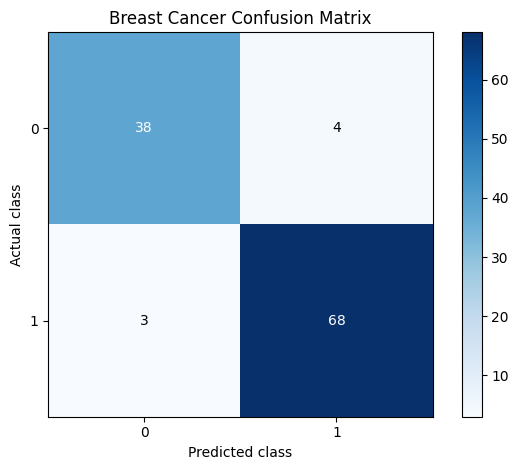

Synthetic
Accuracy: 100.00%
[[2 0]
 [0 2]]
Class 0: {'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}
Class 1: {'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}
Macro: {'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}


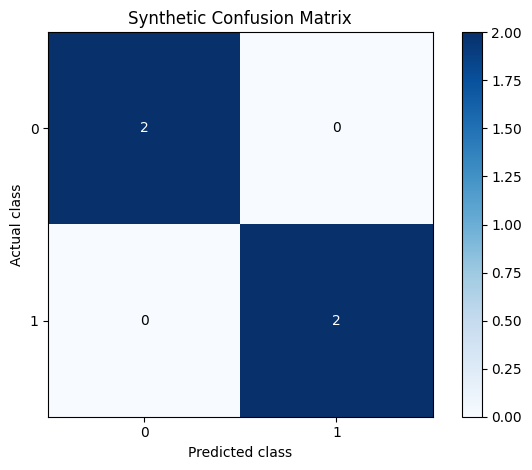

In [12]:
evaluate(y_test, y_pred, model.classes, "Breast Cancer")
evaluate(y_tiny_test, tiny_pred, tiny_model.classes, "Synthetic")

### Breaking the Naive Assumption

Duplicate the most informative feature and compare accuracy and average confidence. Accuracy decreases while confidence initially increases, because the model counts repeated information as independent evidence.


In [13]:
mean_0 = X_train[y_train == 0].mean(axis=0)
mean_1 = X_train[y_train == 1].mean(axis=0)
scores = np.abs(mean_0 - mean_1) / X_train.std(axis=0)
feature_idx = np.argmax(scores)
print("Selected feature:", data.feature_names[feature_idx])

Selected feature: worst concave points


In [14]:
copies = [0, 1, 3, 5, 10]
accuracies = []
confidences = []

for n_copies in copies:
    train_duplicate = np.repeat(
        X_train[:, feature_idx:feature_idx+1], n_copies, axis=1
    )
    test_duplicate = np.repeat(
        X_test[:, feature_idx:feature_idx+1], n_copies, axis=1
    )

    X_train_new = np.hstack([X_train, train_duplicate])
    X_test_new = np.hstack([X_test, test_duplicate])

    experiment_model = GaussianNaiveBayes()
    experiment_model.fit(X_train_new, y_train)
    predictions = experiment_model.predict(X_test_new)
    probabilities = experiment_model.predict_proba(X_test_new)

    acc = accuracy(y_test, predictions)
    confidence = probabilities.max(axis=1).mean()
    accuracies.append(acc)
    confidences.append(confidence)

    print(f"Copies: {n_copies:2d} | Accuracy: {acc:.2%} | Confidence: {confidence:.2%}")

Copies:  0 | Accuracy: 93.81% | Confidence: 99.33%
Copies:  1 | Accuracy: 92.92% | Confidence: 99.62%
Copies:  3 | Accuracy: 92.92% | Confidence: 99.92%
Copies:  5 | Accuracy: 92.92% | Confidence: 99.88%
Copies: 10 | Accuracy: 92.92% | Confidence: 99.31%


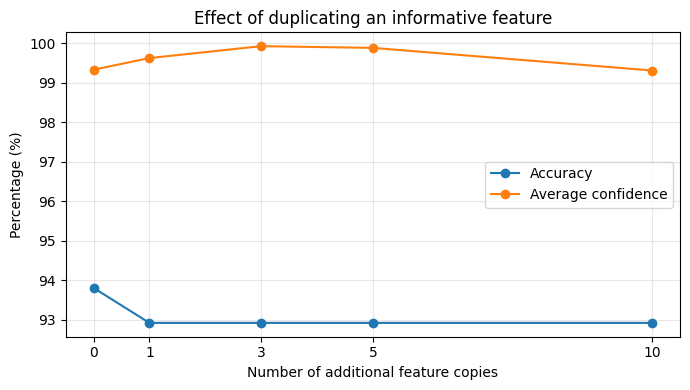

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(copies, np.array(accuracies) * 100, marker="o", label="Accuracy")
plt.plot(copies, np.array(confidences) * 100, marker="o", label="Average confidence")
plt.xticks(copies)
plt.xlabel("Number of additional feature copies")
plt.ylabel("Percentage (%)")
plt.title("Effect of duplicating an informative feature")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

### Fitted Gaussian Curves

Plot a fitted Gaussian for each class and feature, with training samples on the x-axis.


In [16]:
def plot_gaussians(model, X_train, y_train, feature_names):
    for j, name in enumerate(feature_names):
        values = X_train[:, j]
        x = np.linspace(values.min() - values.std(),
                        values.max() + values.std(), 200)

        plt.figure(figsize=(6, 4))

        for i, c in enumerate(model.classes):
            mu = model.theta_[i, j]
            var = model.var_[i, j]

            density = np.exp(-(x - mu)**2 / (2 * var)) / np.sqrt(2 * np.pi * var)
            plt.plot(x, density, color=f"C{i}", label=f"Class {c}")

            points = X_train[y_train == c, j]
            plt.scatter(points, np.zeros(len(points)),
                        color=f"C{i}", s=12, alpha=0.4)

        plt.xlabel(name)
        plt.ylabel("Probability density")
        plt.title(f"Fitted Gaussians — {name}")
        plt.legend()
        plt.tight_layout()
        plt.show()
        plt.close()

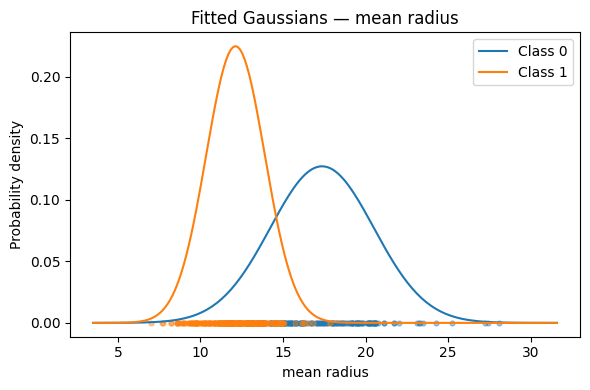

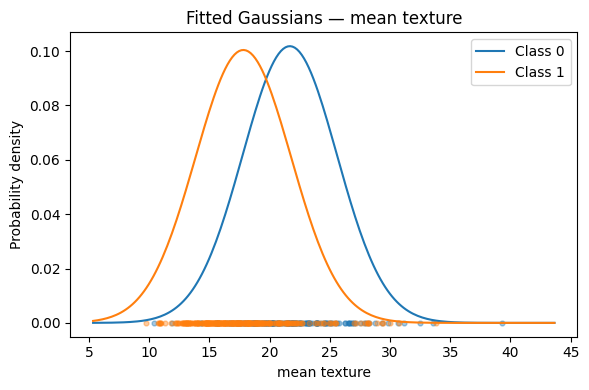

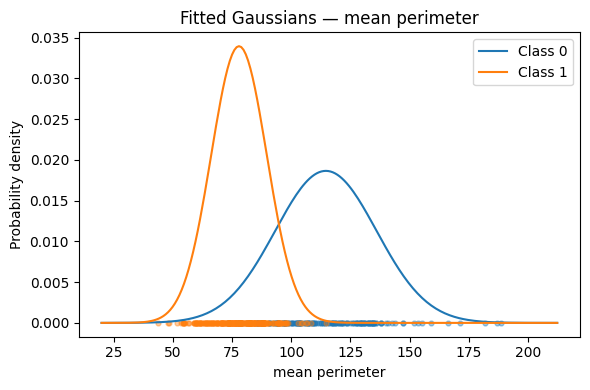

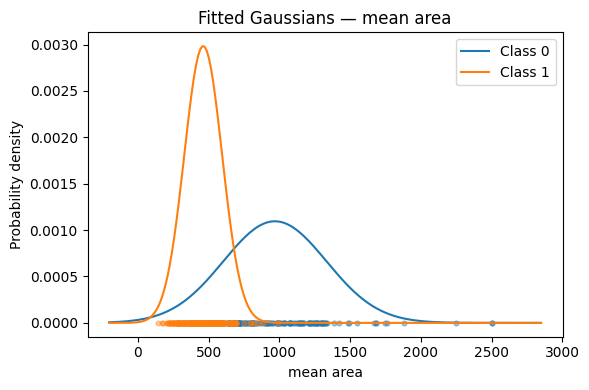

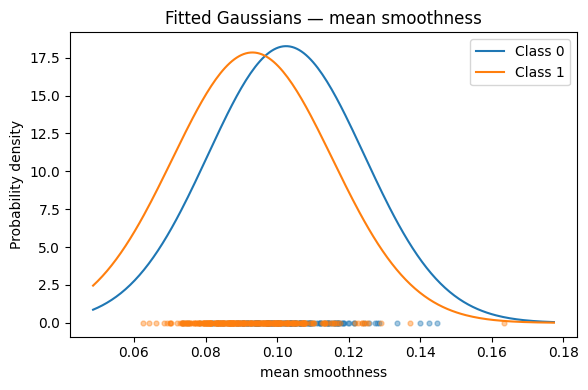

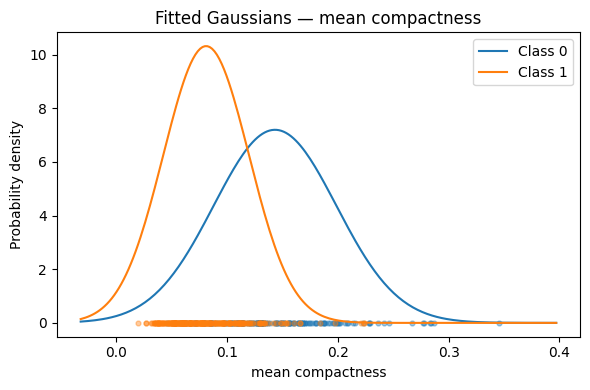

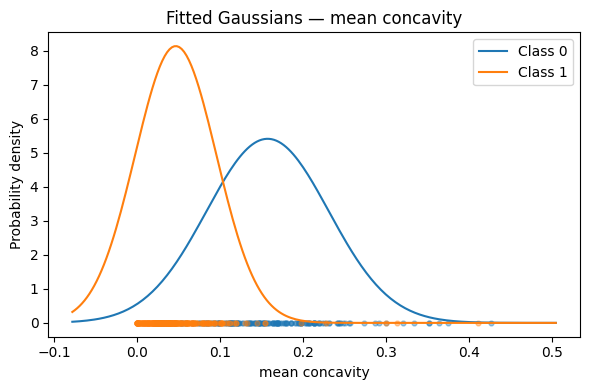

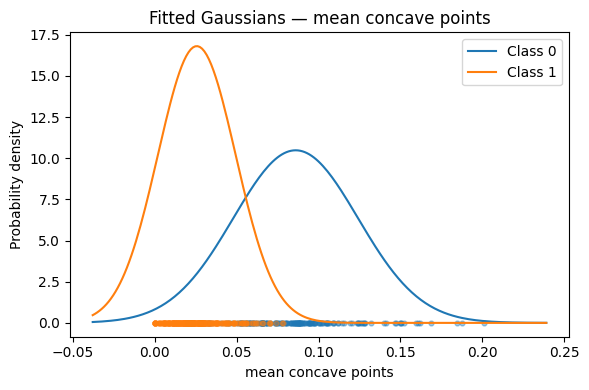

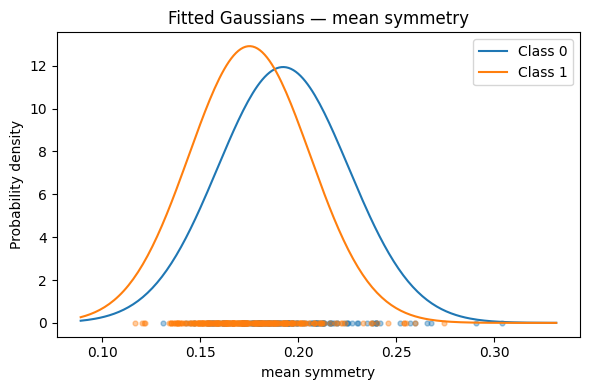

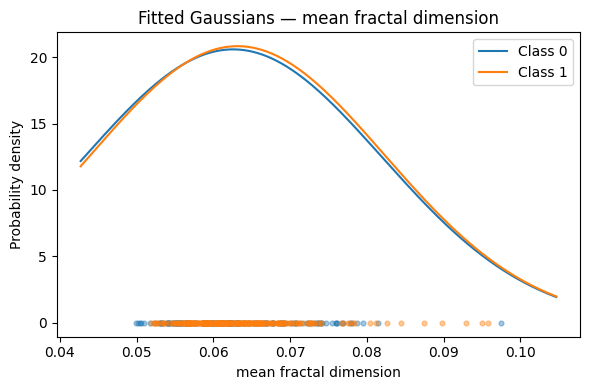

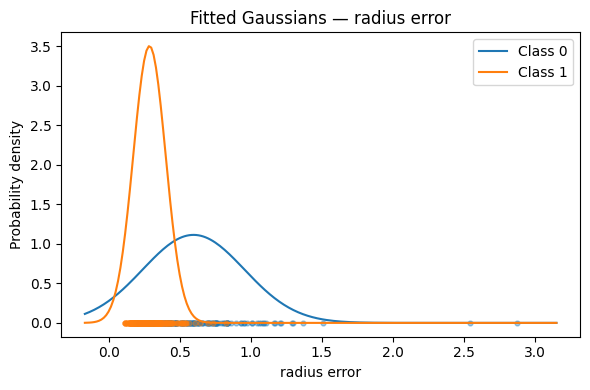

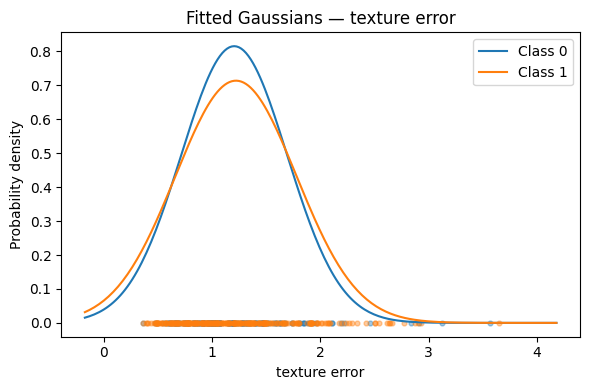

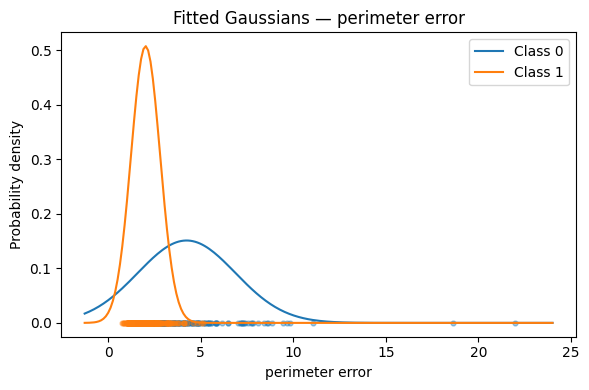

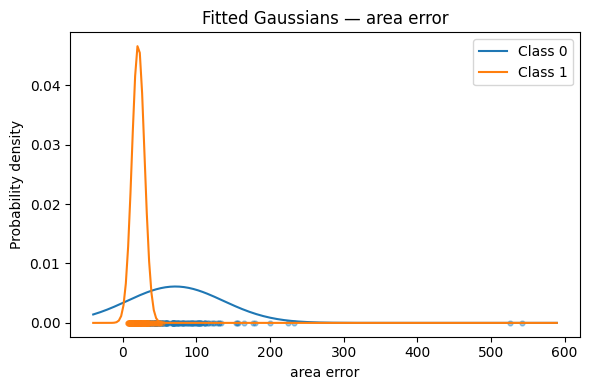

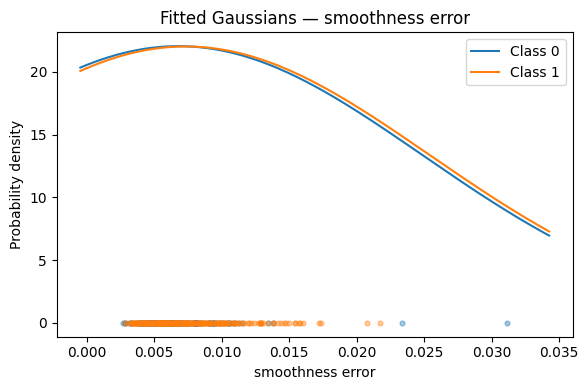

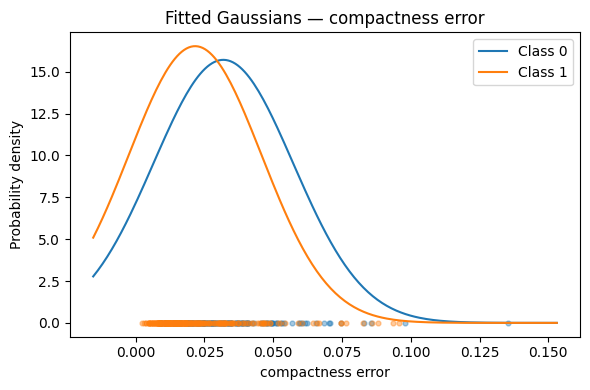

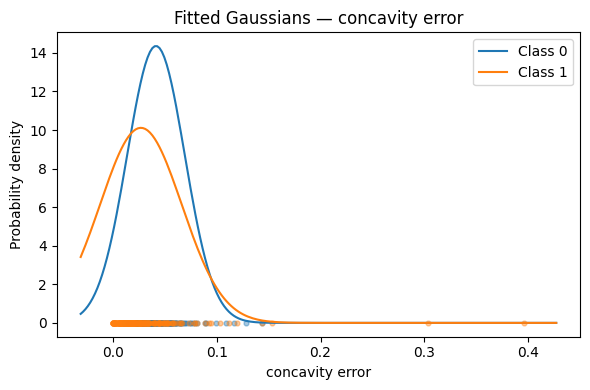

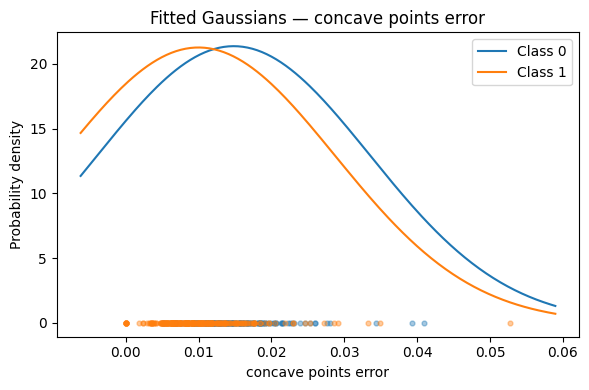

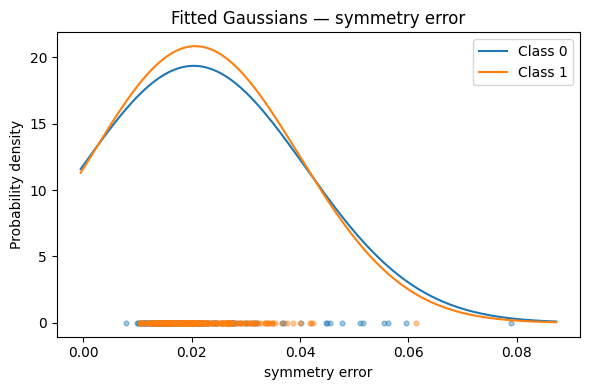

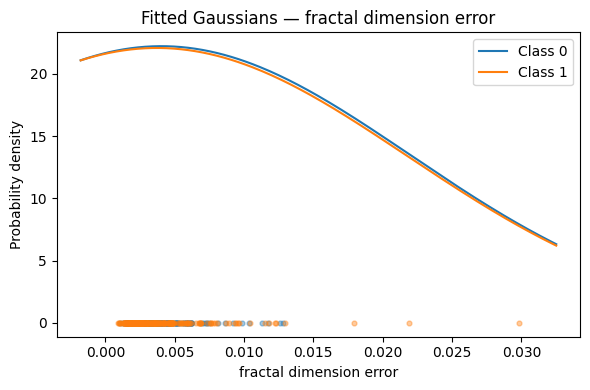

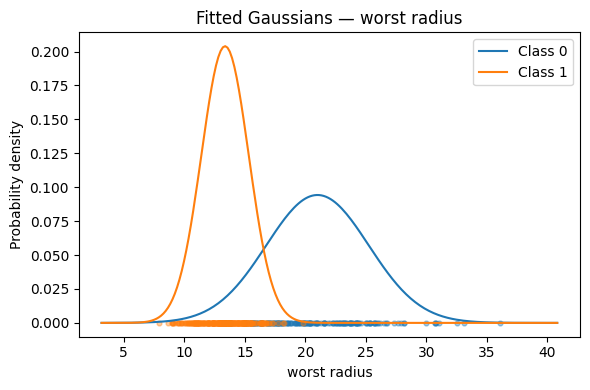

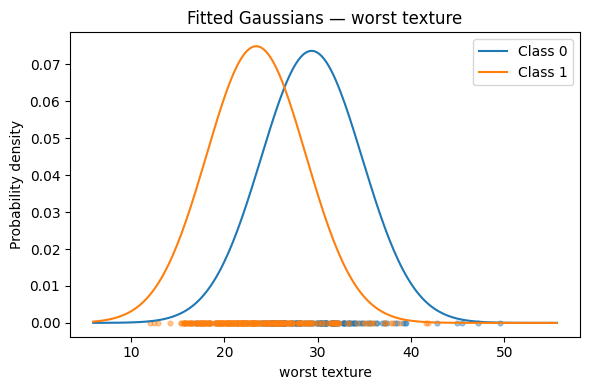

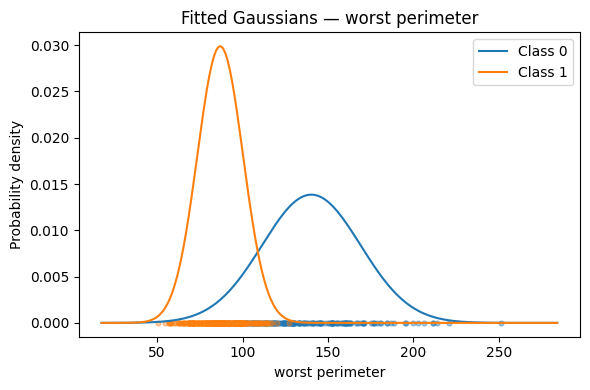

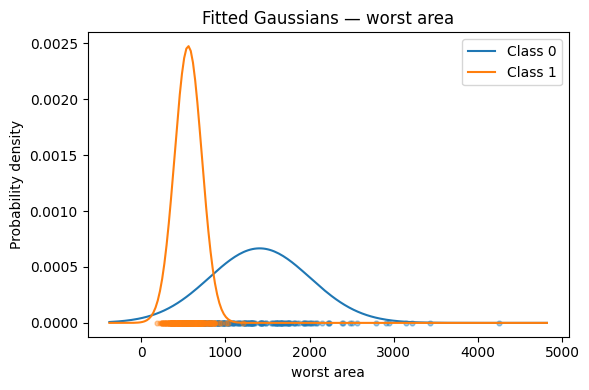

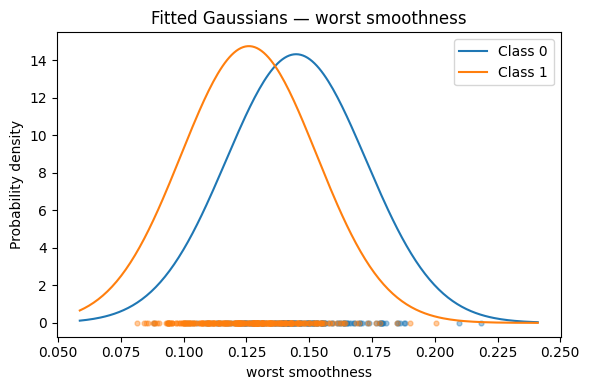

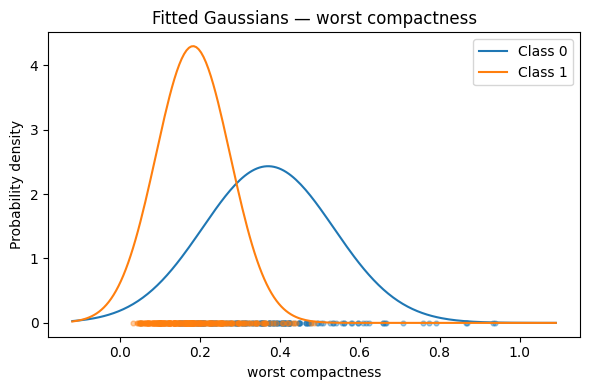

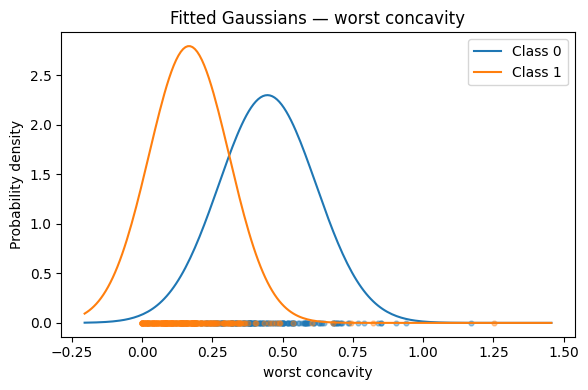

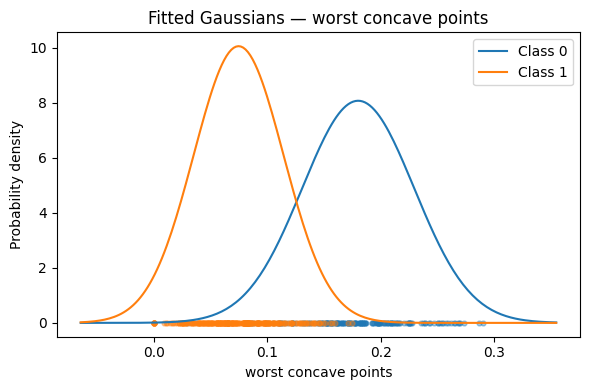

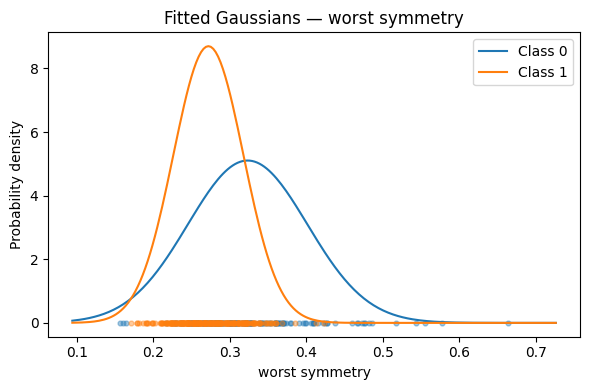

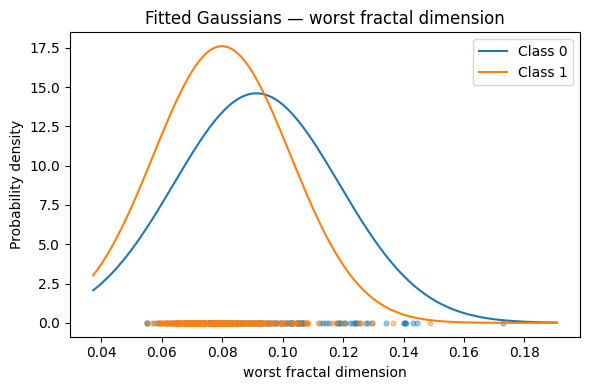

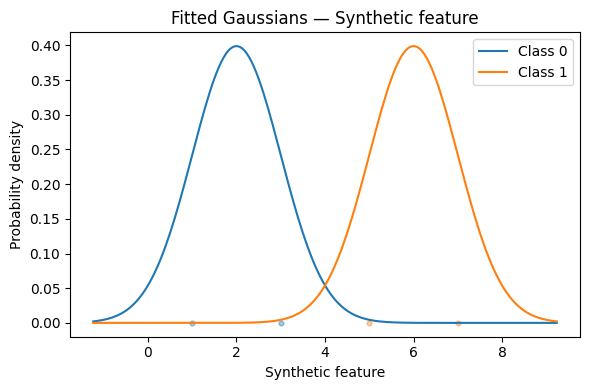

In [17]:
plot_gaussians(model, X_train, y_train, data.feature_names)
plot_gaussians(tiny_model, X_tiny, y_tiny, ["Synthetic feature"])

### Decision Regions

Train a GNB on mean radius and mean texture and predict over a mesh grid. Class-specific variances generally give quadratic boundaries because of squared feature terms. If corresponding variances are equal, these terms cancel and the boundary can be linear.


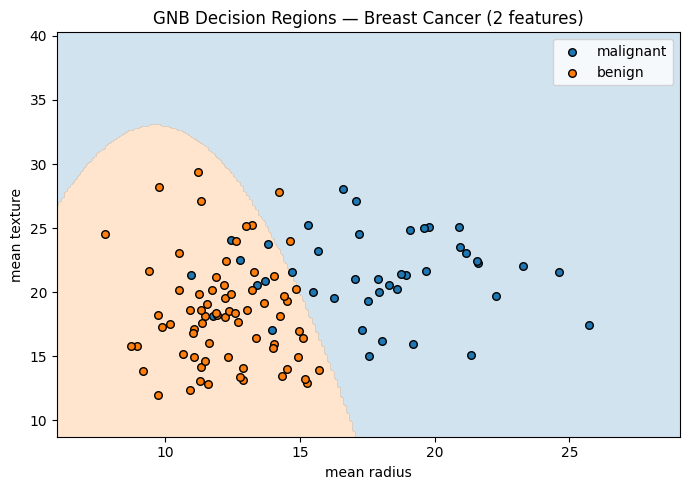

In [18]:
features = [0, 1]
X_train_2d = X_train[:, features]
X_test_2d = X_test[:, features]

model_2d = GaussianNaiveBayes()
model_2d.fit(X_train_2d, y_train)

x1 = np.linspace(min(X_train_2d[:, 0].min(), X_test_2d[:, 0].min()) - 1,
                 max(X_train_2d[:, 0].max(), X_test_2d[:, 0].max()) + 1, 200)
x2 = np.linspace(min(X_train_2d[:, 1].min(), X_test_2d[:, 1].min()) - 1,
                 max(X_train_2d[:, 1].max(), X_test_2d[:, 1].max()) + 1, 200)

xx, yy = np.meshgrid(x1, x2)
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
             colors=["C0", "C1"], alpha=0.2)

for i, c in enumerate(model_2d.classes):
    points = X_test_2d[y_test == c]
    plt.scatter(points[:, 0], points[:, 1], color=f"C{i}",
                edgecolors="black", s=30, label=data.target_names[c])

plt.xlabel(data.feature_names[features[0]])
plt.ylabel(data.feature_names[features[1]])
plt.title("GNB Decision Regions — Breast Cancer (2 features)")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

### Comparison with Scikit-learn

Compare the means, smoothed variances, priors and posterior probabilities using `np.allclose`. Both datasets show 100% prediction agreement with sklearn.


In [19]:
from sklearn.naive_bayes import GaussianNB

def compare_with_sklearn(model, X_train, y_train, X_test, name):
    sklearn_model = GaussianNB(var_smoothing=model.var_smoothing)
    sklearn_model.fit(X_train, y_train)

    print(name)
    print("Means match:", np.allclose(model.theta_, sklearn_model.theta_))
    print("Variances match:", np.allclose(model.var_, sklearn_model.var_))
    print("Class priors match:", np.allclose(model.class_prior_, sklearn_model.class_prior_))
    print("Probabilities match:", np.allclose(
        model.predict_proba(X_test), sklearn_model.predict_proba(X_test)
    ))

    agreement = np.mean(model.predict(X_test) == sklearn_model.predict(X_test))
    print(f"Prediction agreement: {agreement:.2%}")
    print()

compare_with_sklearn(model, X_train, y_train, X_test, "Breast Cancer")
compare_with_sklearn(tiny_model, X_tiny, y_tiny, X_tiny_test, "Synthetic")

Breast Cancer
Means match: True
Variances match: True
Class priors match: True
Probabilities match: True
Prediction agreement: 100.00%

Synthetic
Means match: True
Variances match: True
Class priors match: True
Probabilities match: True
Prediction agreement: 100.00%



### Task 7

### 1. Why is the classifier called "naive"? Give an example where the assumption is clearly false.

The classifier is called naive because it assumes that all features are conditionally independent given the class. This assumption simplifies the calculation of the likelihood. For example, duplicating a feature creates perfectly dependent features, but the classifier treats them as independent and counts the same information multiple times.

### 2. Why can we ignore P(x) when predicting the class?

P(x) is the same for all classes when classifying a given sample. Therefore, dividing by P(x) does not change the order of the posterior probabilities. We can ignore it when predicting the class, but normalization is still needed to obtain posterior probabilities.

### 3. What happens if a feature has zero variance within a class and there is no smoothing?

If a feature has zero variance within a class, the Gaussian likelihood formula involves division by zero. This causes numerical instability and may produce invalid predictions. Variance smoothing solves this problem by adding a small positive value (epsilon) to the variance.

### 4. How is GNB related to Quadratic Discriminant Analysis (QDA)? What extra assumption does GNB make?

Both GNB and QDA assume that the features follow a Gaussian distribution within each class. QDA uses a full covariance matrix, allowing dependencies between features. GNB makes the additional assumption of conditional independence between features, so it uses a diagonal covariance matrix. Therefore, GNB can be considered a special case of QDA.

### 5. GNB trains in one pass over the data. What is its time complexity for training and for predicting one sample (in n, d and k)?

The training time complexity of Gaussian Naive Bayes is O(nd), where n is the number of training samples and d is the number of features. During training, the model estimates the mean, variance, and prior probabilities for each class. Predicting one sample takes O(kd) time because the model calculates the likelihood of each feature for each of the k classes and selects the class with the highest score.